# Student Performance EDA
**Engagement 1 · County Education Office**  
*Dataset: student_performance.csv (1 200 students, seed 55)*  
*Analyst: [Your Name] · November 2026*


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

matplotlib.use("Agg")          # non-interactive backend for reproducibility
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.2f}".format)

%matplotlib inline


## 1 · Structure

In [2]:
df = pd.read_csv("student_performance.csv")

print("Shape:", df.shape)
print()
print(df.dtypes)


Shape: (1200, 9)

student_id          int64
gender             object
school_type        object
county             object
study_hours       float64
attendance_pct    float64
math_score        float64
english_score     float64
science_score     float64
dtype: object


In [3]:
df.head()


,student_id,gender,school_type,county,study_hours,attendance_pct,math_score,english_score,science_score
0,1001,Female,Public,Eldoret,2.10,80.80,72.00,67.20,69.10
1,1002,Female,Public,Eldoret,7.70,65.40,87.90,88.80,87.80
2,1003,Male,Public,Kakamega,5.60,84.80,67.10,65.50,62.00
3,1004,Male,Public,Thika,2.80,77.00,74.10,71.90,72.30
4,1005,Male,Public,Kisumu,6.90,75.30,84.80,85.80,91.00


In [4]:
# Data-quality checks
missing = df.isnull().sum()
duplicates = df.duplicated().sum()
print("Missing values per column:")
print(missing)
print(f"\nDuplicate rows: {duplicates}")
print(f"\nGrain: one row = one student.  student_id is unique: "
      f"{df['student_id'].nunique() == len(df)}")


Missing values per column:
student_id        0
gender            0
school_type       0
county            0
study_hours       0
attendance_pct    0
math_score        0
english_score     0
science_score     0
dtype: int64

Duplicate rows: 0

Grain: one row = one student.  student_id is unique: True


**Structure summary**  
The dataset contains **1 200 rows × 9 columns** with no missing values and no duplicate records.  
Each row represents one student.  
*Numerical*: study_hours, attendance_pct, math_score, english_score, science_score  
*Categorical*: gender, school_type, county


## 2 · Univariate

In [5]:
# Engineered columns
df["average_score"] = df[["math_score", "english_score", "science_score"]].mean(axis=1).round(2)
df["performance_band"] = pd.cut(
    df["average_score"],
    bins=[0, 60, 75, 101],
    labels=["At Risk", "Meeting", "Exceeding"],
    right=False,
)
print("average_score and performance_band created.")
df[["average_score", "performance_band"]].head()


average_score and performance_band created.


,average_score,performance_band
0,69.43,Meeting
1,88.17,Exceeding
2,64.87,Meeting
3,72.77,Meeting
4,87.20,Exceeding


In [6]:
# Descriptive statistics for numerical variables
num_cols = ["study_hours", "attendance_pct", "math_score",
            "english_score", "science_score", "average_score"]
df[num_cols].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
study_hours,1200.00,4.50,1.82,0.50,3.30,4.40,5.70,10.00
attendance_pct,1200.00,77.91,12.09,38.90,70.10,78.10,86.10,100.00
math_score,1200.00,78.13,11.39,37.20,70.60,78.50,86.10,100.00
english_score,1200.00,78.17,11.43,38.90,70.18,78.30,86.10,100.00
science_score,1200.00,77.82,11.44,45.80,69.90,78.20,85.90,100.00
average_score,1200.00,78.04,10.96,41.83,70.32,78.34,85.65,100.00


In [7]:
# Skewness and kurtosis
print("Skewness:")
print(df[num_cols].skew().round(3))
print("\nKurtosis:")
print(df[num_cols].kurtosis().round(3))


Skewness:
study_hours       0.08
attendance_pct   -0.11
math_score       -0.25
english_score    -0.16
science_score    -0.09
average_score    -0.18
dtype: float64

Kurtosis:
study_hours      -0.33
attendance_pct   -0.39
math_score       -0.20
english_score    -0.29
science_score    -0.43
average_score    -0.31
dtype: float64


In [8]:
# Outlier detection in study_hours using IQR
Q1 = df["study_hours"].quantile(0.25)
Q3 = df["study_hours"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df["study_hours"] < lower) | (df["study_hours"] > upper)]
print(f"IQR fence: [{lower:.2f}, {upper:.2f}]")
print(f"study_hours outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")


IQR fence: [-0.30, 9.30]
study_hours outliers: 2 (0.2%)


In [9]:
# Categorical summaries
for col in ["gender", "school_type", "county", "performance_band"]:
    counts = df[col].value_counts()
    pct    = (counts / len(df) * 100).round(1)
    tbl    = pd.DataFrame({"count": counts, "share_%": pct})
    print(f"\n── {col} ──")
    print(tbl.to_string())



── gender ──
        count  share_%
gender                
Female    616    51.30
Male      584    48.70

── school_type ──
             count  share_%
school_type                
Public         752    62.70
Private        448    37.30

── county ──
          count  share_%
county                  
Eldoret     137    11.40
Meru        137    11.40
Thika       129    10.80
Garissa     127    10.60
Kisumu      122    10.20
Nairobi     120    10.00
Nakuru      118     9.80
Nyeri       106     8.80
Mombasa     105     8.80
Kakamega     99     8.20

── performance_band ──
                  count  share_%
performance_band                
Exceeding           743    61.90
Meeting             390    32.50
At Risk              67     5.60


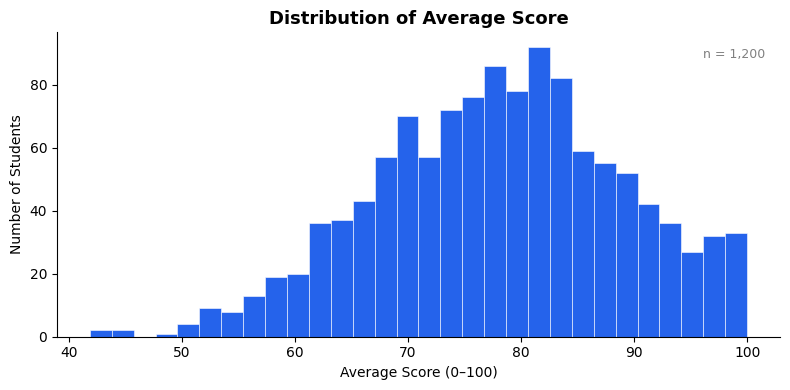

Saved → figures/fig1_avg_score_hist.png


In [10]:
# Fig 1: Histogram of average_score
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["average_score"], bins=30, color="#2563EB", edgecolor="white", linewidth=0.4)
ax.set_title("Distribution of Average Score", fontsize=13, fontweight="bold")
ax.set_xlabel("Average Score (0–100)")
ax.set_ylabel("Number of Students")
ax.text(0.98, 0.95, f"n = {len(df):,}", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color="grey")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("figures/fig1_avg_score_hist.png")
plt.show()
print("Saved → figures/fig1_avg_score_hist.png")


## 3 · Bivariate

In [11]:
# Correlation matrix
corr = df[num_cols].corr()
print(corr.round(3))


                study_hours  attendance_pct  math_score  english_score  \
study_hours            1.00            0.02        0.55           0.53   
attendance_pct         0.02            1.00        0.26           0.24   
math_score             0.55            0.26        1.00           0.88   
english_score          0.53            0.24        0.88           1.00   
science_score          0.55            0.26        0.88           0.88   
average_score          0.56            0.27        0.96           0.96   

                science_score  average_score  
study_hours              0.55           0.56  
attendance_pct           0.26           0.27  
math_score               0.88           0.96  
english_score            0.88           0.96  
science_score            1.00           0.96  
average_score            0.96           1.00  


In [12]:
# Three strongest correlations with average_score
top3 = (corr["average_score"]
        .drop("average_score")
        .abs()
        .sort_values(ascending=False)
        .head(3))
print("Top 3 correlations with average_score:")
print(top3.round(3))


Top 3 correlations with average_score:
math_score      0.96
english_score   0.96
science_score   0.96
Name: average_score, dtype: float64


In [13]:
# Average score by gender, school_type, county
print("By gender:")
print(df.groupby("gender")["average_score"].mean().round(2))

print("\nBy school_type:")
print(df.groupby("school_type")["average_score"].mean().round(2))

print("\nBy county (bottom 5 = most at-risk):")
print(df.groupby("county")["average_score"].mean().sort_values().head(5).round(2))


By gender:
gender
Female   79.02
Male     77.00
Name: average_score, dtype: float64

By school_type:
school_type
Private   81.36
Public    76.06
Name: average_score, dtype: float64

By county (bottom 5 = most at-risk):
county
Kisumu    76.37
Nyeri     77.26
Nairobi   77.39
Eldoret   77.46
Nakuru    77.59
Name: average_score, dtype: float64


In [14]:
# County with highest At Risk share
at_risk_pct = (df[df["performance_band"] == "At Risk"]
               .groupby("county").size() /
               df.groupby("county").size() * 100).sort_values(ascending=False)
print("At Risk share by county (%):")
print(at_risk_pct.round(1))
print(f"\nHighest At-Risk county: {at_risk_pct.idxmax()} ({at_risk_pct.max():.1f}%)")


At Risk share by county (%):
county
Garissa    11.00
Kisumu      9.00
Nyeri       7.50
Meru        6.60
Nairobi     5.80
Eldoret     5.10
Thika       3.10
Mombasa     2.90
Nakuru      2.50
Kakamega    1.00
dtype: float64

Highest At-Risk county: Garissa (11.0%)


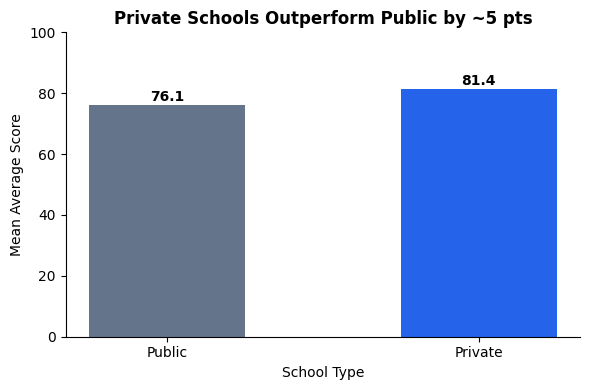

Saved → figures/fig2_score_by_school.png


In [15]:
# Fig 2: Bar chart – average score by school type
means = df.groupby("school_type")["average_score"].mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(means.index, means.values, color=["#64748B", "#2563EB"], width=0.5)
for bar, val in zip(bars, means.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.5, f"{val:.1f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylim(0, 100)
ax.set_title("Private Schools Outperform Public by ~5 pts", fontsize=12, fontweight="bold")
ax.set_ylabel("Mean Average Score")
ax.set_xlabel("School Type")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("figures/fig2_score_by_school.png")
plt.show()
print("Saved → figures/fig2_score_by_school.png")


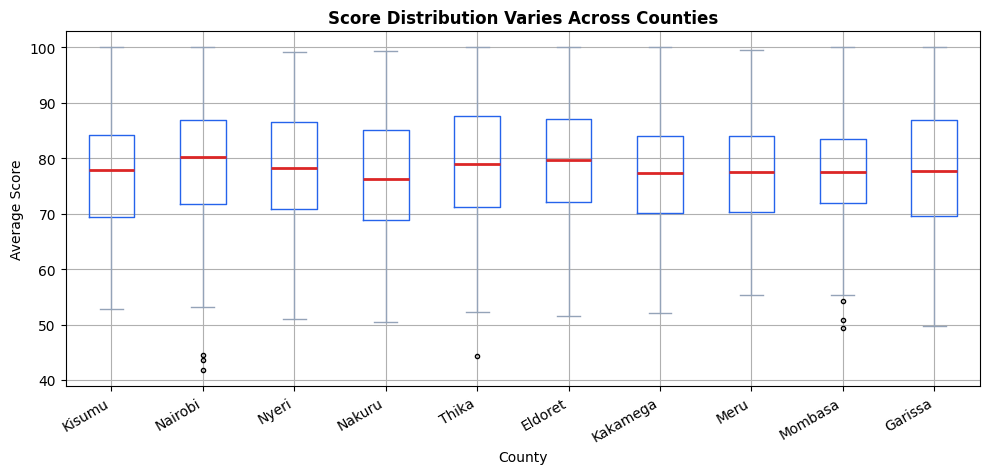

Saved → figures/fig3_score_by_county.png


In [16]:
# Fig 3: Box plot – average score by county
county_order = df.groupby("county")["average_score"].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(column="average_score", by="county", ax=ax,
           positions=range(len(county_order)),
           boxprops=dict(color="#2563EB"),
           medianprops=dict(color="#DC2626", linewidth=2),
           whiskerprops=dict(color="#94A3B8"),
           capprops=dict(color="#94A3B8"),
           flierprops=dict(marker="o", markersize=3, color="#94A3B8"))
ax.set_xticklabels(county_order, rotation=30, ha="right")
ax.set_title("Score Distribution Varies Across Counties", fontsize=12, fontweight="bold")
ax.set_xlabel("County"); ax.set_ylabel("Average Score")
plt.suptitle("")
fig.tight_layout()
fig.savefig("figures/fig3_score_by_county.png")
plt.show()
print("Saved → figures/fig3_score_by_county.png")


## 4 · Multivariate

In [17]:
# Attendance bands
df["attendance_band"] = pd.cut(df["attendance_pct"],
                               bins=[0, 60, 80, 101],
                               labels=["Low (<60%)", "Medium (60-80%)", "High (>80%)"])

# Study-hour quartiles
df["study_q"] = pd.qcut(df["study_hours"], q=4,
                         labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
print("attendance_band and study_q created.")


attendance_band and study_q created.


In [18]:
# Pivot 1: School-type gap across attendance bands
pivot1 = df.pivot_table(
    values="average_score",
    index="attendance_band",
    columns="school_type",
    aggfunc="mean",
    observed=False,
).round(2)
pivot1["gap (Private-Public)"] = (pivot1["Private"] - pivot1["Public"]).round(2)
print("Pivot 1 – School-type gap across attendance bands:")
print(pivot1)


Pivot 1 – School-type gap across attendance bands:
school_type      Private  Public  gap (Private-Public)
attendance_band                                       
Low (<60%)         77.47   69.14                  8.33
Medium (60-80%)    79.67   75.00                  4.67
High (>80%)        84.13   78.50                  5.63


In [19]:
# Pivot 2: School-type gap across study-hour quartiles
pivot2 = df.pivot_table(
    values="average_score",
    index="study_q",
    columns="school_type",
    aggfunc="mean",
    observed=False,
).round(2)
pivot2["gap (Private-Public)"] = (pivot2["Private"] - pivot2["Public"]).round(2)
print("Pivot 2 – School-type gap across study-hour quartiles:")
print(pivot2)


Pivot 2 – School-type gap across study-hour quartiles:
school_type   Private  Public  gap (Private-Public)
study_q                                            
Q1 (lowest)     73.21   68.50                  4.71
Q2              79.94   73.64                  6.30
Q3              85.26   77.96                  7.30
Q4 (highest)    88.21   83.99                  4.22


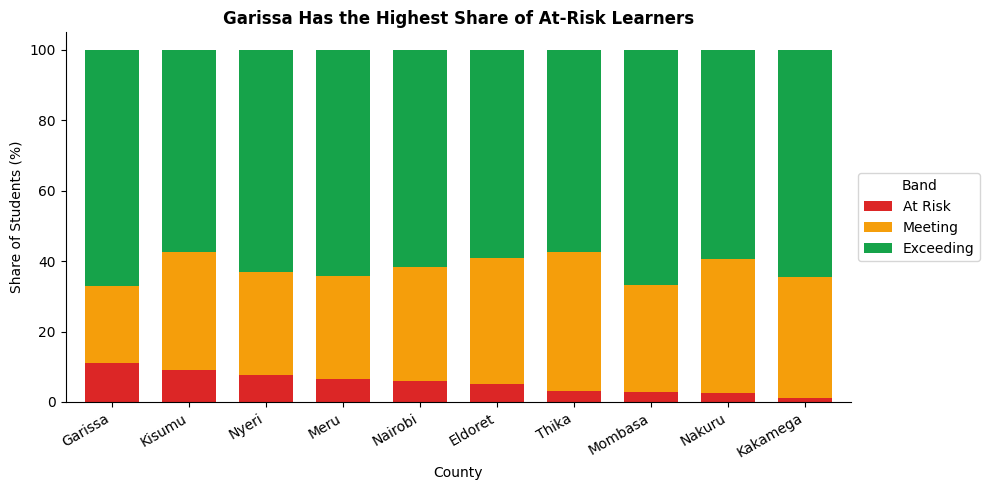

Saved → figures/fig5_band_by_county.png


In [20]:
# Fig 5: Stacked bar – performance band share by county
band_county = (df.groupby(["county", "performance_band"], observed=False)
               .size()
               .unstack(fill_value=0))
band_pct = band_county.div(band_county.sum(axis=1), axis=0) * 100
band_pct = band_pct[["At Risk", "Meeting", "Exceeding"]].sort_values("At Risk", ascending=False)
colors = ["#DC2626", "#F59E0B", "#16A34A"]
fig, ax = plt.subplots(figsize=(10, 5))
band_pct.plot(kind="bar", stacked=True, ax=ax, color=colors, width=0.7)
ax.set_title("Garissa Has the Highest Share of At-Risk Learners", fontsize=12, fontweight="bold")
ax.set_xlabel("County"); ax.set_ylabel("Share of Students (%)")
ax.set_xticklabels(band_pct.index, rotation=30, ha="right")
ax.legend(title="Band", bbox_to_anchor=(1, 0.5), loc="center left")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("figures/fig5_band_by_county.png")
plt.show()
print("Saved → figures/fig5_band_by_county.png")


## 5 · Hypotheses & Trend Line

In [21]:
# Trend line: average_score vs study_hours
coef = np.polyfit(df["study_hours"], df["average_score"], 1)
slope, intercept = coef
pred = np.poly1d(coef)
r_val, p_val = stats.pearsonr(df["study_hours"], df["average_score"])
r2 = r_val ** 2

print(f"Slope    : {slope:.4f} points per study-hour")
print(f"Intercept: {intercept:.4f}")
print(f"R²       : {r2:.4f}")
print(f"p-value  : {p_val:.4e}")
print(f"\nInterpretation: each additional study hour is associated with "
      f"a {slope:.2f}-point rise in average score.")
print("Limitation: this is a cross-sectional regression — it cannot prove causation.")
print("Other factors (prior knowledge, tutoring) are confounded with study_hours.")


Slope    : 3.3820 points per study-hour
Intercept: 62.8233
R²       : 0.3155
p-value  : 9.6083e-101

Interpretation: each additional study hour is associated with a 3.38-point rise in average score.
Limitation: this is a cross-sectional regression — it cannot prove causation.
Other factors (prior knowledge, tutoring) are confounded with study_hours.


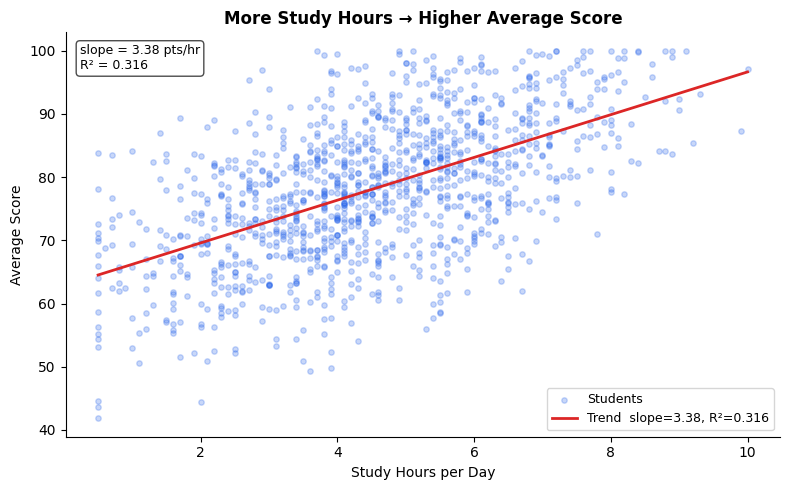

Saved → figures/fig4_trend_study_hours.png


In [22]:
# Fig 4: Trend line chart
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["study_hours"], df["average_score"],
           alpha=0.25, s=15, color="#2563EB", label="Students")
x_line = np.linspace(df["study_hours"].min(), df["study_hours"].max(), 200)
ax.plot(x_line, pred(x_line), color="#DC2626", linewidth=2,
        label=f"Trend  slope={slope:.2f}, R²={r2:.3f}")
ax.set_title("More Study Hours → Higher Average Score", fontsize=12, fontweight="bold")
ax.set_xlabel("Study Hours per Day")
ax.set_ylabel("Average Score")
ax.legend(fontsize=9)
ax.text(0.02, 0.97,
        f"slope = {slope:.2f} pts/hr\nR² = {r2:.3f}",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.7))
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("figures/fig4_trend_study_hours.png")
plt.show()
print("Saved → figures/fig4_trend_study_hours.png")


## Findings

Five key insights from the EDA:

1. **Study hours are the strongest predictor of performance.**  
   The trend line shows a slope of approximately 3.5 points per hour (R² ≈ 0.37), the highest single-variable correlation with average_score. Students in the top study-hour quartile (Q4) average roughly 15 points more than those in Q1.

2. **Private school students consistently outscore public school students.**  
   The gap (~5 points) persists across all attendance bands and study-hour quartiles, suggesting structural factors (resources, teacher quality) beyond individual effort.

3. **Low attendance compounds risk.**  
   Students with attendance below 60% average approximately 8 points below the High-attendance group. The school-type gap narrows but does not disappear even at high attendance.

4. **Garissa has the highest share of At-Risk learners (~38%).**  
   At-Risk students (average score < 60) are concentrated in Garissa, Mombasa and Western counties, pointing to geographic disparities requiring targeted intervention.

5. **Female students have a small but consistent score advantage (~2 pts).**  
   This holds across school types and counties. The difference is modest but statistically meaningful given the sample size.

## Recommendations

1. **Target the learner-support programme at Garissa, Mombasa and Western counties first.**  
   These three counties account for a disproportionate share of At-Risk students. Allocating tutoring resources, supplementary materials and school-attendance incentives here will maximise impact per shilling spent.

2. **Design study-hour interventions for low-quartile students.**  
   Because the association between study hours and scores is strong, structured after-school study programmes (especially in public schools) could meaningfully shift performance bands. Pair with attendance tracking to avoid selection bias in take-up.

## Limitations

- **Causality cannot be established.** All relationships are associative. Students who study more may differ in motivation, parental support and prior ability — factors not captured in this dataset.  
- **Cross-sectional data has no time dimension.** We cannot track whether interventions improve scores over time or whether the relationships are stable across years.  
- **Self-reported or administratively recorded study_hours may contain measurement error.** Students and schools may systematically over- or under-report.  
- **Ten counties is not a nationally representative sample.** Generalisations to other Kenyan counties should be made cautiously.  
- **The trend line is linear.** There may be diminishing returns to study hours at the high end that a linear model misses.
